<a href="https://colab.research.google.com/github/Shubh8306/CSET485-German-Credit-Assignment/blob/main/CSET485_German_Credit_0025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# CSET485 - AI and Society
# Assignment 1
# German Credit Risk Dataset
# Random State = 025 -> 25
# ============================================================

!pip -q install ucimlrepo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    classification_report
)

import statsmodels.api as sm

import warnings
warnings.filterwarnings("ignore")

# Last three digits of roll number = 025
RANDOM_STATE = 25

print("Libraries loaded successfully.")
print("Random state:", RANDOM_STATE)

Libraries loaded successfully.
Random state: 25


In [ ]:
# ============================================================
# DOWNLOAD GERMAN CREDIT DATASET FROM UCI
# ============================================================

german_credit = fetch_ucirepo(id=144)

# Features
X_raw = german_credit.data.features.copy()

# Original target
y_raw = german_credit.data.targets.copy()

print("Dataset downloaded successfully!")
print("Feature shape:", X_raw.shape)
print("Target shape:", y_raw.shape)

display(X_raw.head())

Dataset downloaded successfully!
Feature shape: (1000, 20)
Target shape: (1000, 1)


,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,Attribute11,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201


In [ ]:
# ============================================================
# RENAME DATASET COLUMNS
# ============================================================

column_names = [
    "checking_status",
    "duration",
    "credit_history",
    "purpose",
    "credit_amount",
    "savings_status",
    "employment",
    "installment_rate",
    "personal_status_sex",
    "other_debtors",
    "residence_since",
    "property",
    "age",
    "other_installment_plans",
    "housing",
    "existing_credits",
    "job",
    "dependents",
    "telephone",
    "foreign_worker"
]

X_raw.columns = column_names

# Convert original target to numeric
original_target = pd.to_numeric(
    y_raw.iloc[:, 0],
    errors="coerce"
)

# UCI:
# 1 = Good Credit
# 2 = Bad Credit
#
# Assignment requires:
# 1 = Approve
# 0 = Reject

approval = (original_target == 1).astype(int)

# Create final dataframe
df = X_raw.copy()
df["approval"] = approval.values

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (1000, 21)


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,dependents,telephone,foreign_worker,approval
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,0
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,0


In [ ]:
# ============================================================
# BASIC DATASET INFORMATION
# ============================================================

print("=" * 60)
print("DATASET INFORMATION")
print("=" * 60)

print("\nNumber of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nTarget distribution:")
print(df["approval"].value_counts())

print("\nTarget distribution percentage:")
print(df["approval"].value_counts(normalize=True) * 100)

print("\nMissing values:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)

DATASET INFORMATION

Number of rows: 1000
Number of columns: 21

Target distribution:
approval
1    700
0    300
Name: count, dtype: int64

Target distribution percentage:
approval
1    70.0
0    30.0
Name: proportion, dtype: float64

Missing values:
checking_status            0
duration                   0
credit_history             0
purpose                    0
credit_amount              0
savings_status             0
employment                 0
installment_rate           0
personal_status_sex        0
other_debtors              0
residence_since            0
property                   0
age                        0
other_installment_plans    0
housing                    0
existing_credits           0
job                        0
dependents                 0
telephone                  0
foreign_worker             0
approval                   0
dtype: int64

Data types:
checking_status            object
duration                    int64
credit_history             object
purpose     

In [ ]:
# ============================================================
# CREATE GENDER VARIABLE FOR FAIRNESS ANALYSIS
# ============================================================

def get_gender(code):
    if code in ["A92", "A95"]:
        return "Female"
    elif code in ["A91", "A93", "A94"]:
        return "Male"
    else:
        return "Unknown"

df["gender"] = df["personal_status_sex"].apply(get_gender)

print("Gender distribution:")
print(df["gender"].value_counts())

print("\nGender distribution percentage:")
print(df["gender"].value_counts(normalize=True) * 100)

Gender distribution:
gender
Male      690
Female    310
Name: count, dtype: int64

Gender distribution percentage:
gender
Male      69.0
Female    31.0
Name: proportion, dtype: float64


In [ ]:
# ============================================================
# MISSING VALUES AND DUPLICATES
# ============================================================

missing_values = df.isnull().sum()

print("Total missing values:", missing_values.sum())

if missing_values.sum() == 0:
    print("No missing values found.")
else:
    print("\nMissing values by column:")
    print(missing_values[missing_values > 0])

duplicate_count = df.duplicated().sum()

print("\nNumber of duplicate rows:", duplicate_count)

Total missing values: 0
No missing values found.

Number of duplicate rows: 0


In [ ]:
# ============================================================
# OUTLIER DETECTION USING IQR
# ============================================================

numeric_columns = [
    "duration",
    "credit_amount",
    "installment_rate",
    "residence_since",
    "age",
    "existing_credits",
    "dependents"
]

outlier_results = []

for column in numeric_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_results.append({
        "Feature": column,
        "Outlier Count": len(outliers),
        "Outlier Percentage": round(
            len(outliers) / len(df) * 100, 2
        )
    })

outlier_table = pd.DataFrame(outlier_results)

display(outlier_table)

,Feature,Outlier Count,Outlier Percentage
0,duration,70,7.0
1,credit_amount,72,7.2
2,installment_rate,0,0.0
3,residence_since,0,0.0
4,age,23,2.3
5,existing_credits,6,0.6
6,dependents,155,15.5


In [ ]:
# ============================================================
# DEFINE FEATURES AND TARGET
# ============================================================

# Gender was derived only for fairness analysis.
# Do not use it as an additional model feature because
# the original personal_status_sex feature already contains it.

X = df.drop(columns=["approval", "gender"])

y = df["approval"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nApproval counts:")
print(y.value_counts())

X shape: (1000, 20)
y shape: (1000,)

Approval counts:
approval
1    700
0    300
Name: count, dtype: int64


In [ ]:
# ============================================================
# 70% TRAIN / 30% TEST SPLIT
# Random State = last 3 digits = 025 -> 25
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining percentage:",
      round(len(X_train) / len(X) * 100, 2), "%")

print("Testing percentage:",
      round(len(X_test) / len(X) * 100, 2), "%")

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training samples: 700
Testing samples: 300

Training percentage: 70.0 %
Testing percentage: 30.0 %

Training target distribution:
approval
1    490
0    210
Name: count, dtype: int64

Testing target distribution:
approval
1    210
0     90
Name: count, dtype: int64


In [ ]:
# ============================================================
# PREPROCESSING
# One-Hot Encoding + Standard Scaling
# ============================================================

numeric_features = [
    "duration",
    "credit_amount",
    "installment_rate",
    "residence_since",
    "age",
    "existing_credits",
    "dependents"
]

categorical_features = [
    "checking_status",
    "credit_history",
    "purpose",
    "savings_status",
    "employment",
    "personal_status_sex",
    "other_debtors",
    "property",
    "other_installment_plans",
    "housing",
    "job",
    "telephone",
    "foreign_worker"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

# IMPORTANT:
# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using SAME preprocessing
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("Processed training shape:",
      X_train_processed.shape)

print("Processed testing shape:",
      X_test_processed.shape)

display(X_train_processed.head())

Processed training shape: (700, 48)
Processed testing shape: (300, 48)


,numeric__duration,numeric__credit_amount,numeric__installment_rate,numeric__residence_since,numeric__age,numeric__existing_credits,numeric__dependents,categorical__checking_status_A12,categorical__checking_status_A13,categorical__checking_status_A14,...,categorical__property_A124,categorical__other_installment_plans_A142,categorical__other_installment_plans_A143,categorical__housing_A152,categorical__housing_A153,categorical__job_A172,categorical__job_A173,categorical__job_A174,categorical__telephone_A192,categorical__foreign_worker_A202
697,-0.737234,-0.827531,-1.793105,-0.745839,0.227505,-0.713748,-0.44798,0.0,0.0,1.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
130,2.248192,1.786337,-1.793105,-0.745839,-1.040004,-0.713748,-0.44798,1.0,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
163,-0.903091,1.378752,-0.888149,1.066964,3.124668,-0.713748,-0.44798,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
364,-0.239663,-0.292727,0.921762,-1.652240,-0.949468,-0.713748,-0.44798,0.0,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
379,-1.234806,-1.022508,0.921762,1.066964,1.495014,1.051707,-0.44798,0.0,0.0,1.0,...,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0


In [ ]:
# ============================================================
# MODEL A - OLS LINEAR REGRESSION
# ============================================================

# Add intercept / constant
X_train_ols = sm.add_constant(
    X_train_processed,
    has_constant="add"
)

X_test_ols = sm.add_constant(
    X_test_processed,
    has_constant="add"
)

# Train OLS
ols_model = sm.OLS(
    y_train.astype(float),
    X_train_ols.astype(float)
).fit()

# Predictions
ols_predictions = ols_model.predict(
    X_test_ols.astype(float)
)

print("OLS model trained successfully.")

print("\nFirst 10 predicted values:")
print(ols_predictions.head(10))

OLS model trained successfully.

First 10 predicted values:
596    0.355124
62     0.438242
173    1.100569
535    0.515135
610    0.547677
688    0.930054
263    0.677614
241    0.976798
498    0.909836
112    0.591364
dtype: float64


In [ ]:
# ============================================================
# MODEL A THRESHOLD
# ============================================================

ols_median = np.median(ols_predictions)

ols_class = (
    ols_predictions >= ols_median
).astype(int)

print("Median OLS prediction:", round(ols_median, 4))

print("\nOLS classification counts:")
print(pd.Series(ols_class).value_counts())

Median OLS prediction: 0.7198

OLS classification counts:
0    150
1    150
Name: count, dtype: int64


In [ ]:
# ============================================================
# MODEL B - LOGISTIC REGRESSION
# ============================================================

logistic_model = sm.GLM(
    y_train.astype(float),
    X_train_ols.astype(float),
    family=sm.families.Binomial()
).fit()

logistic_probabilities = logistic_model.predict(
    X_test_ols.astype(float)
)

logistic_class = (
    logistic_probabilities >= 0.5
).astype(int)

print("Logistic Regression trained successfully.")

print("\nFirst 10 probabilities:")
print(logistic_probabilities.head(10))

Logistic Regression trained successfully.

First 10 probabilities:
596    0.244891
62     0.464158
173    0.987629
535    0.496432
610    0.597378
688    0.944819
263    0.734391
241    0.964721
498    0.901561
112    0.570016
dtype: float64


In [ ]:
# ============================================================
# LOGISTIC REGRESSION PERFORMANCE
# ============================================================

logistic_accuracy = accuracy_score(
    y_test,
    logistic_class
)

print(
    "Logistic Regression Accuracy:",
    round(logistic_accuracy, 4)
)

print(
    "Accuracy Percentage:",
    round(logistic_accuracy * 100, 2),
    "%"
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        logistic_class,
        target_names=["Reject", "Approve"]
    )
)

Logistic Regression Accuracy: 0.77
Accuracy Percentage: 77.0 %

Classification Report:
              precision    recall  f1-score   support

      Reject       0.64      0.52      0.58        90
     Approve       0.81      0.88      0.84       210

    accuracy                           0.77       300
   macro avg       0.73      0.70      0.71       300
weighted avg       0.76      0.77      0.76       300



In [ ]:
# ============================================================
# OLS VS LOGISTIC REGRESSION
# ============================================================

comparison_matrix = confusion_matrix(
    ols_class,
    logistic_class
)

print("Agreement / Disagreement Confusion Matrix")
print(comparison_matrix)

mismatches = np.sum(
    ols_class != logistic_class
)

mismatch_percentage = (
    mismatches / len(y_test)
) * 100

agreements = len(y_test) - mismatches

agreement_percentage = (
    agreements / len(y_test)
) * 100

print("\nTotal test cases:", len(y_test))

print("Agreements:", agreements)
print(
    "Agreement percentage:",
    round(agreement_percentage, 2),
    "%"
)

print("\nMismatched cases:", mismatches)
print(
    "Mismatch percentage:",
    round(mismatch_percentage, 2),
    "%"
)

print(
    "\nOLS median threshold:",
    round(ols_median, 4)
)

print("Logistic threshold: 0.5")

Agreement / Disagreement Confusion Matrix
[[ 73  77]
 [  0 150]]

Total test cases: 300
Agreements: 223
Agreement percentage: 74.33 %

Mismatched cases: 77
Mismatch percentage: 25.67 %

OLS median threshold: 0.7198
Logistic threshold: 0.5


In [ ]:
# ============================================================
# PART 2.1 - SIMPSON'S PARADOX
# GROUPING VARIABLE: GENDER
# ============================================================

from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm

# We will use the TRAINING SET for this analysis
# so our analysis remains consistent with model development.

simpson_columns = [
    "duration",
    "credit_amount",
    "installment_rate",
    "residence_since",
    "age",
    "existing_credits",
    "dependents"
]

simpson_df = df.loc[
    X_train.index,
    simpson_columns + ["gender", "approval"]
].copy()

print("Total rows:", len(simpson_df))

print("\nGender counts:")
print(simpson_df["gender"].value_counts())

print("\nApproval rate by gender:")
print(
    simpson_df.groupby("gender")["approval"]
    .agg(["count", "mean"])
)

display(simpson_df.head())

Total rows: 700

Gender counts:
gender
Male      483
Female    217
Name: count, dtype: int64

Approval rate by gender:
        count      mean
gender                 
Female    217  0.654378
Male      483  0.720497


,duration,credit_amount,installment_rate,residence_since,age,existing_credits,dependents,gender,approval
697,12,926,1,2,38,1,1,Female,1
130,48,8487,1,2,24,1,1,Female,1
163,10,7308,2,4,70,1,1,Male,1
364,18,2473,4,1,25,1,1,Male,0
379,6,362,4,4,52,2,1,Female,1


In [ ]:
# ============================================================
# STANDARDIZE NUMERIC VARIABLES
# ============================================================

scaler_simpson = StandardScaler()

simpson_df[simpson_columns] = scaler_simpson.fit_transform(
    simpson_df[simpson_columns]
)

print("Variables standardized successfully.")

display(
    simpson_df[
        simpson_columns + ["gender", "approval"]
    ].head()
)

Variables standardized successfully.


,duration,credit_amount,installment_rate,residence_since,age,existing_credits,dependents,gender,approval
697,-0.737234,-0.827531,-1.793105,-0.745839,0.227505,-0.713748,-0.44798,Female,1
130,2.248192,1.786337,-1.793105,-0.745839,-1.040004,-0.713748,-0.44798,Female,1
163,-0.903091,1.378752,-0.888149,1.066964,3.124668,-0.713748,-0.44798,Male,1
364,-0.239663,-0.292727,0.921762,-1.652240,-0.949468,-0.713748,-0.44798,Male,0
379,-1.234806,-1.022508,0.921762,1.066964,1.495014,1.051707,-0.44798,Female,1


In [ ]:
# ============================================================
# FIT LOGISTIC REGRESSION FOR:
# 1. FULL DATA
# 2. MALE
# 3. FEMALE
# ============================================================

def fit_group_logistic(data):

    X_group = data[simpson_columns].copy()
    y_group = data["approval"].astype(float)

    X_group = sm.add_constant(
        X_group,
        has_constant="add"
    )

    model = sm.GLM(
        y_group,
        X_group.astype(float),
        family=sm.families.Binomial()
    ).fit()

    return model


# Full population
full_simpson_model = fit_group_logistic(
    simpson_df
)

# Male population
male_simpson_model = fit_group_logistic(
    simpson_df[
        simpson_df["gender"] == "Male"
    ]
)

# Female population
female_simpson_model = fit_group_logistic(
    simpson_df[
        simpson_df["gender"] == "Female"
    ]
)

print("All three logistic models trained successfully.")

print("\nFull sample size:",
      len(simpson_df))

print(
    "Male sample size:",
    len(simpson_df[
        simpson_df["gender"] == "Male"
    ])
)

print(
    "Female sample size:",
    len(simpson_df[
        simpson_df["gender"] == "Female"
    ])
)

All three logistic models trained successfully.

Full sample size: 700
Male sample size: 483
Female sample size: 217


In [ ]:
# ============================================================
# COMPARE REGRESSION COEFFICIENTS
# ============================================================

results = []

for feature in simpson_columns:

    full_ci = full_simpson_model.conf_int().loc[feature]
    male_ci = male_simpson_model.conf_int().loc[feature]
    female_ci = female_simpson_model.conf_int().loc[feature]

    results.append({

        "Predictor": feature,

        "Full Coef":
            full_simpson_model.params[feature],

        "Full CI Lower":
            full_ci[0],

        "Full CI Upper":
            full_ci[1],

        "Full p-value":
            full_simpson_model.pvalues[feature],

        "Male Coef":
            male_simpson_model.params[feature],

        "Male CI Lower":
            male_ci[0],

        "Male CI Upper":
            male_ci[1],

        "Male p-value":
            male_simpson_model.pvalues[feature],

        "Female Coef":
            female_simpson_model.params[feature],

        "Female CI Lower":
            female_ci[0],

        "Female CI Upper":
            female_ci[1],

        "Female p-value":
            female_simpson_model.pvalues[feature]

    })


simpson_results = pd.DataFrame(results)

# Round only for display
display(
    simpson_results.round(4)
)

,Predictor,Full Coef,Full CI Lower,Full CI Upper,Full p-value,Male Coef,Male CI Lower,Male CI Upper,Male p-value,Female Coef,Female CI Lower,Female CI Upper,Female p-value
0,duration,-0.3493,-0.5661,-0.1326,0.0016,-0.3539,-0.6033,-0.1045,0.0054,-0.5043,-0.9709,-0.0376,0.0342
1,credit_amount,-0.2620,-0.4928,-0.0311,0.0261,-0.3009,-0.5678,-0.0339,0.0272,-0.1959,-0.6853,0.2935,0.4327
2,installment_rate,-0.1843,-0.3777,0.0090,0.0617,-0.1266,-0.3712,0.1181,0.3106,-0.3824,-0.7218,-0.0430,0.0272
3,residence_since,0.0031,-0.1727,0.1788,0.9729,0.1479,-0.0850,0.3808,0.2133,-0.1333,-0.4207,0.1541,0.3633
4,age,0.1342,-0.0510,0.3194,0.1555,-0.0674,-0.3016,0.1669,0.5728,0.4081,0.0695,0.7467,0.0182
5,existing_credits,0.1776,-0.0042,0.3594,0.0556,0.2305,0.0084,0.4526,0.0419,-0.0313,-0.3541,0.2915,0.8492
6,dependents,-0.0540,-0.2252,0.1172,0.5362,-0.0619,-0.2517,0.1279,0.5225,-0.4210,-0.9264,0.0845,0.1026


In [ ]:
# ============================================================
# SEARCH FOR SIMPSON-TYPE REVERSALS
# ============================================================

reversals = []

for _, row in simpson_results.iterrows():

    full_coef = row["Full Coef"]
    male_coef = row["Male Coef"]
    female_coef = row["Female Coef"]

    # Classic Simpson-type reversal:
    # both subgroups point in same direction
    # but overall coefficient points opposite

    if (
        np.sign(male_coef) == np.sign(female_coef)
        and
        np.sign(full_coef) != np.sign(male_coef)
    ):

        reversals.append(
            row["Predictor"]
        )


if len(reversals) > 0:

    print("SIMpson-type reversal found!")

    print(
        "Predictor(s):",
        reversals
    )

else:

    print(
        "No strict sign reversal found."
    )

    print(
        "We will check for the strongest subgroup difference instead."
    )

No strict sign reversal found.
We will check for the strongest subgroup difference instead.


In [ ]:
# ============================================================
# FIND STRONGEST SUBGROUP COEFFICIENT DIFFERENCE
# ============================================================

simpson_results["Male-Female Difference"] = abs(
    simpson_results["Male Coef"]
    -
    simpson_results["Female Coef"]
)

difference_table = simpson_results.sort_values(
    "Male-Female Difference",
    ascending=False
)

display(
    difference_table[
        [
            "Predictor",
            "Full Coef",
            "Male Coef",
            "Female Coef",
            "Male-Female Difference",
            "Full p-value",
            "Male p-value",
            "Female p-value"
        ]
    ].round(4)
)


strongest_predictor = difference_table.iloc[0]["Predictor"]

print(
    "\nLargest subgroup difference:",
    strongest_predictor
)

print(
    "Difference:",
    round(
        difference_table.iloc[0][
            "Male-Female Difference"
        ],
        4
    )
)

,Predictor,Full Coef,Male Coef,Female Coef,Male-Female Difference,Full p-value,Male p-value,Female p-value
4,age,0.1342,-0.0674,0.4081,0.4755,0.1555,0.5728,0.0182
6,dependents,-0.0540,-0.0619,-0.4210,0.3591,0.5362,0.5225,0.1026
3,residence_since,0.0031,0.1479,-0.1333,0.2812,0.9729,0.2133,0.3633
5,existing_credits,0.1776,0.2305,-0.0313,0.2618,0.0556,0.0419,0.8492
2,installment_rate,-0.1843,-0.1266,-0.3824,0.2559,0.0617,0.3106,0.0272
0,duration,-0.3493,-0.3539,-0.5043,0.1504,0.0016,0.0054,0.0342
1,credit_amount,-0.2620,-0.3009,-0.1959,0.1050,0.0261,0.0272,0.4327



Largest subgroup difference: age
Difference: 0.4755


In [ ]:
# ============================================================
# PART 2.2 - OMITTED VARIABLE BIAS
# Confounding variable: CREDIT AMOUNT
# ============================================================

print("Processed feature names:")

for feature in X_train_processed.columns:
    print(feature)

Processed feature names:
numeric__duration
numeric__credit_amount
numeric__installment_rate
numeric__residence_since
numeric__age
numeric__existing_credits
numeric__dependents
categorical__checking_status_A12
categorical__checking_status_A13
categorical__checking_status_A14
categorical__credit_history_A31
categorical__credit_history_A32
categorical__credit_history_A33
categorical__credit_history_A34
categorical__purpose_A41
categorical__purpose_A410
categorical__purpose_A42
categorical__purpose_A43
categorical__purpose_A44
categorical__purpose_A45
categorical__purpose_A46
categorical__purpose_A48
categorical__purpose_A49
categorical__savings_status_A62
categorical__savings_status_A63
categorical__savings_status_A64
categorical__savings_status_A65
categorical__employment_A72
categorical__employment_A73
categorical__employment_A74
categorical__employment_A75
categorical__personal_status_sex_A92
categorical__personal_status_sex_A93
categorical__personal_status_sex_A94
categorical__other_d

In [ ]:
# ============================================================
# FULL MODEL VS REDUCED MODEL
# Drop: credit_amount
# ============================================================

confounder = "numeric__credit_amount"

# FULL MODEL
X_full = X_train_processed.copy()

X_full_const = sm.add_constant(
    X_full,
    has_constant="add"
)

full_ovb_model = sm.GLM(
    y_train.astype(float),
    X_full_const.astype(float),
    family=sm.families.Binomial()
).fit()


# REDUCED MODEL
# Remove credit amount
X_reduced = X_train_processed.drop(
    columns=[confounder]
)

X_reduced_const = sm.add_constant(
    X_reduced,
    has_constant="add"
)

reduced_ovb_model = sm.GLM(
    y_train.astype(float),
    X_reduced_const.astype(float),
    family=sm.families.Binomial()
).fit()


print("Full model trained successfully.")
print("Reduced model trained successfully.")

print("\nDropped variable:", confounder)

print(
    "Full model feature count:",
    X_full.shape[1]
)

print(
    "Reduced model feature count:",
    X_reduced.shape[1]
)

Full model trained successfully.
Reduced model trained successfully.

Dropped variable: numeric__credit_amount
Full model feature count: 48
Reduced model feature count: 47


In [ ]:
# ============================================================
# COMPARE BEFORE / AFTER COEFFICIENTS
# ============================================================

common_features = [
    feature
    for feature in reduced_ovb_model.params.index
    if feature != "const"
]

ovb_results = []

for feature in common_features:

    before = full_ovb_model.params[feature]
    after = reduced_ovb_model.params[feature]

    # Percentage change
    if abs(before) > 1e-10:
        percentage_change = (
            abs(after - before) /
            abs(before)
        ) * 100
    else:
        percentage_change = np.nan

    ovb_results.append({
        "Predictor": feature,
        "Full Model Coef": before,
        "Reduced Model Coef": after,
        "Absolute Change": abs(after - before),
        "Percentage Change": percentage_change
    })


ovb_table = pd.DataFrame(ovb_results)

ovb_table = ovb_table.sort_values(
    "Percentage Change",
    ascending=False
)

display(
    ovb_table.round(4)
)

,Predictor,Full Model Coef,Reduced Model Coef,Absolute Change,Percentage Change
27,categorical__employment_A73,0.0696,-0.0658,0.1354,194.4367
3,numeric__age,0.0126,-0.0037,0.0164,129.4565
43,categorical__job_A173,-0.1451,0.0369,0.1820,125.4018
42,categorical__job_A172,-0.1512,0.0173,0.1685,111.4688
9,categorical__credit_history_A31,-0.2251,-0.0641,0.1610,71.5149
35,categorical__property_A122,-0.0944,-0.1572,0.0628,66.6041
26,categorical__employment_A72,0.1684,0.0565,0.1119,66.4441
1,numeric__installment_rate,-0.2526,-0.1312,0.1214,48.0537
0,numeric__duration,-0.4448,-0.6236,0.1788,40.1870
36,categorical__property_A123,-0.1553,-0.2151,0.0598,38.5079


In [ ]:
# ============================================================
# TOP 10 COEFFICIENT SHIFTS
# ============================================================

top_changes = ovb_table.head(10)

display(
    top_changes.round(4)
)

largest_change = top_changes.iloc[0]

print("\nPredictor with largest percentage change:")
print(largest_change["Predictor"])

print(
    "\nFull model coefficient:",
    round(
        largest_change["Full Model Coef"],
        4
    )
)

print(
    "Reduced model coefficient:",
    round(
        largest_change["Reduced Model Coef"],
        4
    )
)

print(
    "Percentage change:",
    round(
        largest_change["Percentage Change"],
        2
    ),
    "%"
)

,Predictor,Full Model Coef,Reduced Model Coef,Absolute Change,Percentage Change
27,categorical__employment_A73,0.0696,-0.0658,0.1354,194.4367
3,numeric__age,0.0126,-0.0037,0.0164,129.4565
43,categorical__job_A173,-0.1451,0.0369,0.1820,125.4018
42,categorical__job_A172,-0.1512,0.0173,0.1685,111.4688
9,categorical__credit_history_A31,-0.2251,-0.0641,0.1610,71.5149
35,categorical__property_A122,-0.0944,-0.1572,0.0628,66.6041
26,categorical__employment_A72,0.1684,0.0565,0.1119,66.4441
1,numeric__installment_rate,-0.2526,-0.1312,0.1214,48.0537
0,numeric__duration,-0.4448,-0.6236,0.1788,40.1870
36,categorical__property_A123,-0.1553,-0.2151,0.0598,38.5079



Predictor with largest percentage change:
categorical__employment_A73

Full model coefficient: 0.0696
Reduced model coefficient: -0.0658
Percentage change: 194.44 %


In [ ]:
# ============================================================
# REPORT TABLE - TOP 4 CHANGES
# ============================================================

report_ovb_table = (
    ovb_table
    .head(4)
    .copy()
)

report_ovb_table[
    "Full Model Coef"
] = report_ovb_table[
    "Full Model Coef"
].round(4)

report_ovb_table[
    "Reduced Model Coef"
] = report_ovb_table[
    "Reduced Model Coef"
].round(4)

report_ovb_table[
    "Absolute Change"
] = report_ovb_table[
    "Absolute Change"
].round(4)

report_ovb_table[
    "Percentage Change"
] = report_ovb_table[
    "Percentage Change"
].round(2)

display(report_ovb_table)

,Predictor,Full Model Coef,Reduced Model Coef,Absolute Change,Percentage Change
27,categorical__employment_A73,0.0696,-0.0658,0.1354,194.44
3,numeric__age,0.0126,-0.0037,0.0164,129.46
43,categorical__job_A173,-0.1451,0.0369,0.1820,125.40
42,categorical__job_A172,-0.1512,0.0173,0.1685,111.47


In [ ]:
# ============================================================
# RELATIONSHIP OF CREDIT AMOUNT WITH OTHER VARIABLES
# ============================================================

numeric_correlation_columns = [
    "credit_amount",
    "duration",
    "installment_rate",
    "residence_since",
    "age",
    "existing_credits",
    "dependents",
    "approval"
]

correlations = (
    df[numeric_correlation_columns]
    .corr(numeric_only=True)["credit_amount"]
    .sort_values(ascending=False)
)

print(
    "Correlation with credit_amount:"
)

display(
    correlations.to_frame(
        "Correlation"
    ).round(4)
)

Correlation with credit_amount:


,Correlation
credit_amount,1.0000
duration,0.6250
age,0.0327
residence_since,0.0289
existing_credits,0.0208
dependents,0.0171
approval,-0.1547
installment_rate,-0.2713


In [ ]:
# ============================================================
# PART 2.3 - ADVERSARIAL SUBSET
# HIGH-CONFIDENCE WRONG PREDICTIONS
# ============================================================

# Build a test-results dataframe using the ORIGINAL features
test_results = X_test.copy()

test_results["gender"] = df.loc[X_test.index, "gender"]
test_results["actual"] = y_test
test_results["predicted_probability"] = logistic_probabilities
test_results["predicted_class"] = logistic_class

# High-confidence wrong predictions:
# 1. Probability >= 0.75 but actual = 0
# 2. Probability <= 0.25 but actual = 1

high_conf_wrong = test_results[
    (
        (test_results["predicted_probability"] >= 0.75)
        &
        (test_results["actual"] == 0)
    )
    |
    (
        (test_results["predicted_probability"] <= 0.25)
        &
        (test_results["actual"] == 1)
    )
].copy()


# Label type of error
high_conf_wrong["error_type"] = np.where(
    (
        (high_conf_wrong["predicted_probability"] >= 0.75)
        &
        (high_conf_wrong["actual"] == 0)
    ),
    "Confident False Approval",
    "Confident False Rejection"
)


total_high_conf_wrong = len(high_conf_wrong)

high_conf_wrong_percentage = (
    total_high_conf_wrong / len(test_results)
) * 100


print("Total test cases:", len(test_results))

print(
    "High-confidence wrong predictions:",
    total_high_conf_wrong
)

print(
    "Percentage of test set:",
    round(high_conf_wrong_percentage, 2),
    "%"
)

print("\nError types:")
print(high_conf_wrong["error_type"].value_counts())

Total test cases: 300
High-confidence wrong predictions: 28
Percentage of test set: 9.33 %

Error types:
error_type
Confident False Approval     19
Confident False Rejection     9
Name: count, dtype: int64


In [ ]:
# ============================================================
# SELECT APPROXIMATELY 50 ADVERSARIAL ROWS
# ============================================================

if len(high_conf_wrong) > 50:

    adversarial_subset = high_conf_wrong.sample(
        n=50,
        random_state=RANDOM_STATE
    )

else:

    adversarial_subset = high_conf_wrong.copy()


print(
    "Rows in adversarial subset:",
    len(adversarial_subset)
)

display(
    adversarial_subset[
        [
            "age",
            "gender",
            "duration",
            "credit_amount",
            "installment_rate",
            "actual",
            "predicted_probability",
            "predicted_class",
            "error_type"
        ]
    ].head(50)
)

Rows in adversarial subset: 28


,age,gender,duration,credit_amount,installment_rate,actual,predicted_probability,predicted_class,error_type
846,68,Male,18,6761,2,0,0.846243,1,Confident False Approval
278,32,Female,6,4611,1,0,0.909481,1,Confident False Approval
194,21,Male,45,3031,4,0,0.830085,1,Confident False Approval
650,50,Male,48,7476,4,1,0.173355,0,Confident False Rejection
505,27,Male,10,1309,4,0,0.989299,1,Confident False Approval
218,24,Male,24,3021,2,1,0.236436,0,Confident False Rejection
409,28,Male,12,939,4,0,0.899634,1,Confident False Approval
876,36,Male,18,1940,3,1,0.170533,0,Confident False Rejection
614,22,Female,18,1808,4,0,0.920629,1,Confident False Approval
349,32,Male,9,1136,4,0,0.896534,1,Confident False Approval


In [ ]:
# ============================================================
# AGE COMPARISON
# ADVERSARIAL SUBSET VS FULL TEST SET
# ============================================================

age_comparison = pd.DataFrame({

    "Full Test Set": [
        test_results["age"].mean(),
        test_results["age"].median(),
        test_results["age"].min(),
        test_results["age"].max(),
        test_results["age"].std()
    ],

    "Adversarial Subset": [
        adversarial_subset["age"].mean(),
        adversarial_subset["age"].median(),
        adversarial_subset["age"].min(),
        adversarial_subset["age"].max(),
        adversarial_subset["age"].std()
    ]

}, index=[
    "Mean Age",
    "Median Age",
    "Minimum Age",
    "Maximum Age",
    "Age Std Dev"
])

display(age_comparison.round(2))

,Full Test Set,Adversarial Subset
Mean Age,35.68,35.79
Median Age,32.00,32.00
Minimum Age,19.00,21.00
Maximum Age,75.00,68.00
Age Std Dev,12.11,13.01


In [ ]:
# ============================================================
# GENDER COMPARISON
# ============================================================

full_gender = (
    test_results["gender"]
    .value_counts(normalize=True)
    .mul(100)
)

adversarial_gender = (
    adversarial_subset["gender"]
    .value_counts(normalize=True)
    .mul(100)
)

gender_comparison = pd.DataFrame({
    "Full Test Set %": full_gender,
    "Adversarial Subset %": adversarial_gender
}).fillna(0)

display(
    gender_comparison.round(2)
)

,Full Test Set %,Adversarial Subset %
gender,,
Male,69.0,89.29
Female,31.0,10.71


In [ ]:
# ============================================================
# FINANCIAL CHARACTERISTICS
# ============================================================

comparison_features = [
    "duration",
    "credit_amount",
    "installment_rate",
    "age",
    "existing_credits",
    "dependents"
]

characteristic_comparison = pd.DataFrame({

    "Full Test Mean":
        test_results[
            comparison_features
        ].mean(),

    "Adversarial Mean":
        adversarial_subset[
            comparison_features
        ].mean()

})

characteristic_comparison[
    "Difference"
] = (
    characteristic_comparison["Adversarial Mean"]
    -
    characteristic_comparison["Full Test Mean"]
)

display(
    characteristic_comparison.round(2)
)

,Full Test Mean,Adversarial Mean,Difference
duration,20.93,23.68,2.75
credit_amount,3158.10,4986.50,1828.40
installment_rate,2.95,3.04,0.08
age,35.68,35.79,0.10
existing_credits,1.41,1.50,0.09
dependents,1.13,1.04,-0.09


In [ ]:
# ============================================================
# SEARCH FOR COMMON NUMERIC CHARACTERISTICS
# ============================================================

numeric_search_features = [
    "duration",
    "credit_amount",
    "installment_rate",
    "age",
    "existing_credits",
    "dependents"
]

numeric_traits = []

for feature in numeric_search_features:

    median_value = test_results[feature].median()

    # HIGH characteristic
    full_high = (
        test_results[feature] >= median_value
    ).mean() * 100

    adv_high = (
        adversarial_subset[feature] >= median_value
    ).mean() * 100

    numeric_traits.append({
        "Characteristic":
            f"{feature} >= {median_value:.2f}",

        "Adversarial %":
            adv_high,

        "Full Test %":
            full_high,

        "Difference":
            adv_high - full_high
    })


    # LOW characteristic
    full_low = (
        test_results[feature] < median_value
    ).mean() * 100

    adv_low = (
        adversarial_subset[feature] < median_value
    ).mean() * 100

    numeric_traits.append({
        "Characteristic":
            f"{feature} < {median_value:.2f}",

        "Adversarial %":
            adv_low,

        "Full Test %":
            full_low,

        "Difference":
            adv_low - full_low
    })


numeric_traits_table = pd.DataFrame(
    numeric_traits
)

numeric_traits_table = numeric_traits_table.sort_values(
    "Difference",
    ascending=False
)

display(
    numeric_traits_table.round(2)
)

,Characteristic,Adversarial %,Full Test %,Difference
2,credit_amount >= 2290.00,64.29,50.00,14.29
0,duration >= 18.00,64.29,58.00,6.29
5,installment_rate < 3.00,39.29,37.67,1.62
7,age < 32.00,46.43,46.33,0.10
10,dependents >= 1.00,100.00,100.00,0.00
11,dependents < 1.00,0.00,0.00,0.00
9,existing_credits < 1.00,0.00,0.00,0.00
8,existing_credits >= 1.00,100.00,100.00,0.00
6,age >= 32.00,53.57,53.67,-0.10
4,installment_rate >= 3.00,60.71,62.33,-1.62


In [ ]:
# ============================================================
# SEARCH CATEGORICAL CHARACTERISTICS
# ============================================================

categorical_search_features = [
    "checking_status",
    "credit_history",
    "purpose",
    "savings_status",
    "employment",
    "personal_status_sex",
    "property",
    "housing",
    "job",
    "foreign_worker"
]

category_traits = []

for feature in categorical_search_features:

    categories = test_results[feature].dropna().unique()

    for category in categories:

        full_pct = (
            test_results[feature] == category
        ).mean() * 100

        adv_pct = (
            adversarial_subset[feature] == category
        ).mean() * 100

        category_traits.append({

            "Feature": feature,

            "Category": category,

            "Adversarial %": adv_pct,

            "Full Test %": full_pct,

            "Difference": adv_pct - full_pct
        })


category_traits_table = pd.DataFrame(
    category_traits
)

category_traits_table = category_traits_table.sort_values(
    "Difference",
    ascending=False
)

display(
    category_traits_table.head(15).round(2)
)

,Feature,Category,Adversarial %,Full Test %,Difference
41,job,A174,35.71,14.67,21.05
30,personal_status_sex,A93,67.86,53.67,14.19
23,savings_status,A65,32.14,19.00,13.14
36,property,A122,35.71,23.67,12.05
28,employment,A71,17.86,6.67,11.19
10,purpose,A49,17.86,10.67,7.19
38,housing,A153,17.86,10.67,7.19
34,property,A124,21.43,15.00,6.43
31,personal_status_sex,A91,10.71,5.00,5.71
12,purpose,A46,10.71,5.00,5.71


In [ ]:
# ============================================================
# CONFIDENCE ANALYSIS
# ============================================================

print("Probability summary of adversarial cases:")

display(
    adversarial_subset[
        "predicted_probability"
    ].describe().round(4)
)


print("\nConfident false approvals:")

display(
    adversarial_subset[
        adversarial_subset[
            "error_type"
        ] == "Confident False Approval"
    ][
        [
            "age",
            "gender",
            "duration",
            "credit_amount",
            "predicted_probability",
            "actual"
        ]
    ].head(10)
)


print("\nConfident false rejections:")

display(
    adversarial_subset[
        adversarial_subset[
            "error_type"
        ] == "Confident False Rejection"
    ][
        [
            "age",
            "gender",
            "duration",
            "credit_amount",
            "predicted_probability",
            "actual"
        ]
    ].head(10)
)

Probability summary of adversarial cases:


,predicted_probability
count,28.0000
mean,0.6464
std,0.3658
min,0.0217
25%,0.1726
50%,0.8363
75%,0.9137
max,1.0000



Confident false approvals:


,age,gender,duration,credit_amount,predicted_probability,actual
846,68,Male,18,6761,0.846243,0
278,32,Female,6,4611,0.909481,0
194,21,Male,45,3031,0.830085,0
505,27,Male,10,1309,0.989299,0
409,28,Male,12,939,0.899634,0
614,22,Female,18,1808,0.920629,0
349,32,Male,9,1136,0.896534,0
56,52,Male,12,6468,0.842611,0
850,33,Male,20,2235,0.792386,0
949,31,Male,24,3621,0.939248,0



Confident false rejections:


,age,gender,duration,credit_amount,predicted_probability,actual
650,50,Male,48,7476,0.173355,1
218,24,Male,24,3021,0.236436,1
876,36,Male,18,1940,0.170533,1
272,36,Male,48,12169,0.057187,1
17,25,Male,30,8072,0.128650,1
818,43,Male,36,15857,0.021743,1
615,48,Male,48,12204,0.139762,1
438,65,Male,42,3394,0.135260,1
986,33,Male,42,6289,0.130858,1


In [ ]:
# ============================================================
# COEFFICIENTS RELATED TO ADVERSARIAL SUBSET
# ============================================================

important_terms = [
    "credit_amount",
    "duration",
    "personal_status_sex",
    "job_A174",
    "savings_status"
]

important_coefficients = []

for feature in logistic_model.params.index:

    if any(term in feature for term in important_terms):

        coef = logistic_model.params[feature]

        important_coefficients.append({
            "Feature": feature,
            "Coefficient": coef,
            "Odds Ratio": np.exp(coef)
        })


important_coef_table = pd.DataFrame(
    important_coefficients
)

important_coef_table = important_coef_table.sort_values(
    "Coefficient",
    ascending=False
)

display(
    important_coef_table.round(4)
)

,Feature,Coefficient,Odds Ratio
4,categorical__savings_status_A64,1.4255,4.1600
7,categorical__personal_status_sex_A93,0.9758,2.6532
5,categorical__savings_status_A65,0.7993,2.2240
2,categorical__savings_status_A62,0.4970,1.6438
3,categorical__savings_status_A63,0.3491,1.4179
6,categorical__personal_status_sex_A92,0.3254,1.3846
8,categorical__personal_status_sex_A94,0.3225,1.3806
9,categorical__job_A174,-0.1932,0.8243
1,numeric__credit_amount,-0.3570,0.6997
0,numeric__duration,-0.4448,0.6409


In [ ]:
# ============================================================
# PART 2.4 - FAIRNESS TRADE-OFF ANALYSIS
# Sensitive Variable: Gender
#
# Group A = Male
# Group B = Female
# ============================================================

fairness_df = pd.DataFrame({
    "actual": y_test.astype(int),
    "probability": logistic_probabilities,
    "gender": df.loc[y_test.index, "gender"]
})

print("Fairness dataset size:", len(fairness_df))

print("\nGender distribution:")
print(fairness_df["gender"].value_counts())

print("\nActual approval rate by gender:")

display(
    fairness_df.groupby("gender")["actual"]
    .agg(["count", "mean"])
    .round(4)
)

Fairness dataset size: 300

Gender distribution:
gender
Male      207
Female     93
Name: count, dtype: int64

Actual approval rate by gender:


,count,mean
gender,,
Female,93,0.6344
Male,207,0.7295


In [ ]:
# ============================================================
# FAIRNESS METRIC FUNCTIONS
# ============================================================

def safe_ratio(a, b):
    """
    Safely calculate a/b.
    Returns NaN if denominator is zero.
    """
    if b == 0 or pd.isna(b):
        return np.nan
    return a / b


def calculate_group_metrics(data, threshold, group):

    subset = data[
        data["gender"] == group
    ].copy()

    actual = subset["actual"].values

    predicted = (
        subset["probability"].values >= threshold
    ).astype(int)


    # Confusion matrix components
    TP = np.sum(
        (predicted == 1) &
        (actual == 1)
    )

    TN = np.sum(
        (predicted == 0) &
        (actual == 0)
    )

    FP = np.sum(
        (predicted == 1) &
        (actual == 0)
    )

    FN = np.sum(
        (predicted == 0) &
        (actual == 1)
    )


    # Positive prediction / approval rate
    selection_rate = predicted.mean()


    # True Positive Rate
    TPR = (
        TP / (TP + FN)
        if (TP + FN) > 0
        else np.nan
    )


    # False Positive Rate
    FPR = (
        FP / (FP + TN)
        if (FP + TN) > 0
        else np.nan
    )


    # Positive Predictive Value / Precision
    PPV = (
        TP / (TP + FP)
        if (TP + FP) > 0
        else np.nan
    )


    return {
        "Selection Rate": selection_rate,
        "TPR": TPR,
        "FPR": FPR,
        "PPV": PPV,
        "TP": TP,
        "TN": TN,
        "FP": FP,
        "FN": FN
    }


print("Fairness functions created successfully.")

Fairness functions created successfully.


In [ ]:
# ============================================================
# THRESHOLD SWEEP
# 0.05, 0.15, 0.25 ... 0.95
# ============================================================

thresholds = np.arange(
    0.05,
    1.00,
    0.10
)

fairness_results = []


for threshold in thresholds:

    threshold = round(
        float(threshold),
        2
    )


    # Male = Group A
    male = calculate_group_metrics(
        fairness_df,
        threshold,
        "Male"
    )


    # Female = Group B
    female = calculate_group_metrics(
        fairness_df,
        threshold,
        "Female"
    )


    # ------------------------------
    # DEMOGRAPHIC PARITY
    # ------------------------------

    DP = safe_ratio(
        male["Selection Rate"],
        female["Selection Rate"]
    )


    # ------------------------------
    # EQUALIZED ODDS
    # Assignment formula:
    #
    # min(
    #   TPR_A / TPR_B,
    #   FPR_A / FPR_B
    # )
    # ------------------------------

    tpr_ratio = safe_ratio(
        male["TPR"],
        female["TPR"]
    )

    fpr_ratio = safe_ratio(
        male["FPR"],
        female["FPR"]
    )


    if (
        pd.notna(tpr_ratio)
        and
        pd.notna(fpr_ratio)
    ):
        EO = min(
            tpr_ratio,
            fpr_ratio
        )
    else:
        EO = np.nan


    # ------------------------------
    # PREDICTIVE PARITY
    # ------------------------------

    PP = safe_ratio(
        male["PPV"],
        female["PPV"]
    )


    # Overall predictions
    overall_prediction = (
        fairness_df["probability"] >= threshold
    ).astype(int)


    overall_accuracy = accuracy_score(
        fairness_df["actual"],
        overall_prediction
    )


    fairness_results.append({

        "Threshold": threshold,

        "DP": DP,

        "EO": EO,

        "PP": PP,

        "Accuracy": overall_accuracy,

        "Male Approval Rate":
            male["Selection Rate"],

        "Female Approval Rate":
            female["Selection Rate"],

        "Male TPR":
            male["TPR"],

        "Female TPR":
            female["TPR"],

        "Male FPR":
            male["FPR"],

        "Female FPR":
            female["FPR"],

        "Male PPV":
            male["PPV"],

        "Female PPV":
            female["PPV"]

    })


fairness_table = pd.DataFrame(
    fairness_results
)


display(
    fairness_table.round(4)
)

,Threshold,DP,EO,PP,Accuracy,Male Approval Rate,Female Approval Rate,Male TPR,Female TPR,Male FPR,Female FPR,Male PPV,Female PPV
0,0.05,1.0060,0.9934,1.1354,0.7000,0.9952,0.9892,0.9934,1.0000,1.0000,0.9706,0.7282,0.6413
1,0.15,0.9834,0.9603,1.1228,0.7033,0.9517,0.9677,0.9603,1.0000,0.9286,0.9118,0.7360,0.6556
2,0.25,1.0109,0.9404,1.0697,0.7300,0.9130,0.9032,0.9404,1.0000,0.8393,0.7353,0.7513,0.7024
3,0.35,1.0928,0.9804,1.0315,0.7400,0.8696,0.7957,0.9139,0.9322,0.7500,0.5588,0.7667,0.7432
4,0.45,1.1668,1.0100,0.9953,0.7633,0.8406,0.7204,0.9073,0.8983,0.6607,0.4118,0.7874,0.7910
5,0.55,1.2355,1.0127,0.9425,0.7733,0.7440,0.6022,0.8411,0.8305,0.4821,0.2059,0.8247,0.8750
6,0.65,1.4210,1.1521,0.9323,0.7300,0.6570,0.4624,0.7616,0.6610,0.3750,0.1176,0.8456,0.9070
7,0.75,1.3591,1.1088,0.9381,0.7100,0.5845,0.4301,0.6954,0.6271,0.2857,0.0882,0.8678,0.9250
8,0.85,1.4527,1.2140,0.9610,0.6433,0.4686,0.3226,0.5762,0.4746,0.1786,0.0588,0.8969,0.9333
9,0.95,2.2014,NaN,0.9184,0.4700,0.2367,0.1075,0.2980,0.1695,0.0714,0.0000,0.9184,1.0000


In [ ]:
# ============================================================
# CLEAN FAIRNESS TABLE FOR REPORT
# ============================================================

fairness_report_table = fairness_table[
    [
        "Threshold",
        "DP",
        "EO",
        "PP",
        "Accuracy"
    ]
].copy()


display(
    fairness_report_table.round(4)
)

,Threshold,DP,EO,PP,Accuracy
0,0.05,1.0060,0.9934,1.1354,0.7000
1,0.15,0.9834,0.9603,1.1228,0.7033
2,0.25,1.0109,0.9404,1.0697,0.7300
3,0.35,1.0928,0.9804,1.0315,0.7400
4,0.45,1.1668,1.0100,0.9953,0.7633
5,0.55,1.2355,1.0127,0.9425,0.7733
6,0.65,1.4210,1.1521,0.9323,0.7300
7,0.75,1.3591,1.1088,0.9381,0.7100
8,0.85,1.4527,1.2140,0.9610,0.6433
9,0.95,2.2014,NaN,0.9184,0.4700


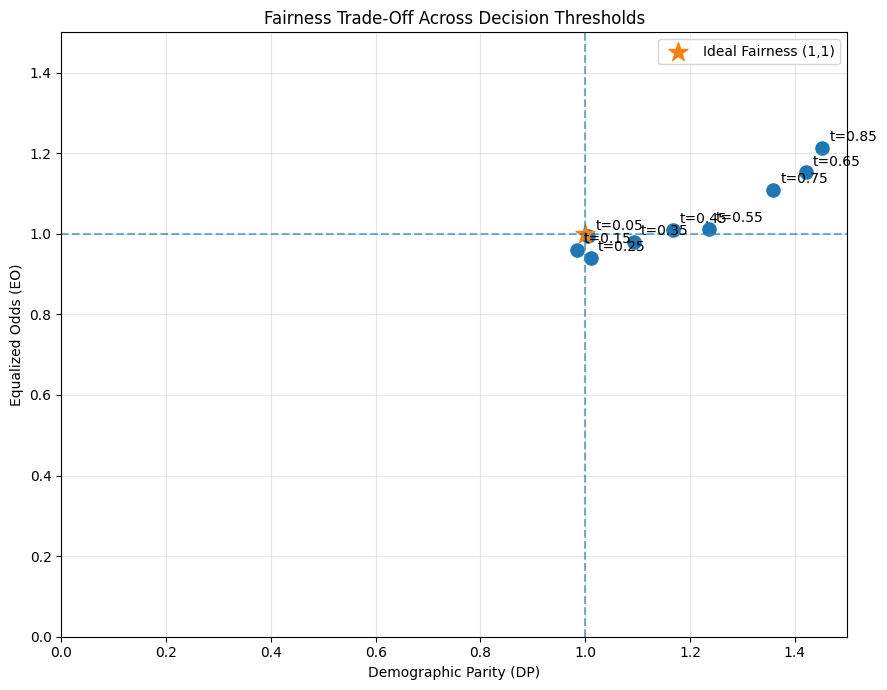

Graph saved as fairness_tradeoff.png


In [ ]:
# ============================================================
# FAIRNESS TRADE-OFF CHART
# X = Demographic Parity
# Y = Equalized Odds
# ============================================================

plot_data = fairness_table.dropna(
    subset=["DP", "EO"]
)


plt.figure(figsize=(9, 7))


plt.scatter(
    plot_data["DP"],
    plot_data["EO"],
    s=90
)


# Add threshold label beside every point
for _, row in plot_data.iterrows():

    plt.annotate(
        f't={row["Threshold"]:.2f}',
        (
            row["DP"],
            row["EO"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )


# Ideal fairness point
plt.scatter(
    1,
    1,
    marker="*",
    s=200,
    label="Ideal Fairness (1,1)"
)


plt.axvline(
    x=1,
    linestyle="--",
    alpha=0.6
)

plt.axhline(
    y=1,
    linestyle="--",
    alpha=0.6
)


plt.xlabel(
    "Demographic Parity (DP)"
)

plt.ylabel(
    "Equalized Odds (EO)"
)

plt.title(
    "Fairness Trade-Off Across Decision Thresholds"
)


plt.xlim(0, 1.5)
plt.ylim(0, 1.5)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()


# Save high-quality graph for report
plt.savefig(
    "fairness_tradeoff.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print(
    "Graph saved as fairness_tradeoff.png"
)

In [ ]:
# ============================================================
# DISTANCE FROM IDEAL FAIRNESS
# Ideal DP = EO = PP = 1
# ============================================================

fairness_analysis = fairness_table.copy()


fairness_analysis["DP Distance"] = abs(
    fairness_analysis["DP"] - 1
)

fairness_analysis["EO Distance"] = abs(
    fairness_analysis["EO"] - 1
)

fairness_analysis["PP Distance"] = abs(
    fairness_analysis["PP"] - 1
)


fairness_analysis[
    "Combined Fairness Distance"
] = (
    fairness_analysis["DP Distance"]
    +
    fairness_analysis["EO Distance"]
    +
    fairness_analysis["PP Distance"]
)


display(
    fairness_analysis[
        [
            "Threshold",
            "DP",
            "EO",
            "PP",
            "Accuracy",
            "Combined Fairness Distance"
        ]
    ]
    .sort_values(
        "Combined Fairness Distance"
    )
    .round(4)
)

,Threshold,DP,EO,PP,Accuracy,Combined Fairness Distance
2,0.25,1.0109,0.9404,1.0697,0.7300,0.1402
3,0.35,1.0928,0.9804,1.0315,0.7400,0.1440
0,0.05,1.0060,0.9934,1.1354,0.7000,0.1480
1,0.15,0.9834,0.9603,1.1228,0.7033,0.1791
4,0.45,1.1668,1.0100,0.9953,0.7633,0.1814
5,0.55,1.2355,1.0127,0.9425,0.7733,0.3057
7,0.75,1.3591,1.1088,0.9381,0.7100,0.5298
6,0.65,1.4210,1.1521,0.9323,0.7300,0.6408
8,0.85,1.4527,1.2140,0.9610,0.6433,0.7057
9,0.95,2.2014,NaN,0.9184,0.4700,NaN


In [ ]:
# ============================================================
# SAVE IMPORTANT RESULTS
# ============================================================

fairness_table.to_csv(
    "fairness_metrics_025.csv",
    index=False
)

report_ovb_table.to_csv(
    "omitted_variable_results_025.csv",
    index=False
)

adversarial_subset.to_csv(
    "adversarial_subset_025.csv",
    index=False
)

simpson_results.to_csv(
    "subgroup_analysis_025.csv",
    index=False
)


print("Results saved successfully.")

print("\nFiles created:")
print("1. fairness_metrics_025.csv")
print("2. omitted_variable_results_025.csv")
print("3. adversarial_subset_025.csv")
print("4. subgroup_analysis_025.csv")
print("5. fairness_tradeoff.png")

Results saved successfully.

Files created:
1. fairness_metrics_025.csv
2. omitted_variable_results_025.csv
3. adversarial_subset_025.csv
4. subgroup_analysis_025.csv
5. fairness_tradeoff.png


In [ ]:
# ============================================================
# DETAILED RESULTS FOR CHOSEN THRESHOLD = 0.35
# ============================================================

chosen_threshold = 0.35

chosen_row = fairness_table[
    fairness_table["Threshold"] == chosen_threshold
]

print("=" * 65)
print("CHOSEN FAIRNESS THRESHOLD:", chosen_threshold)
print("=" * 65)

display(
    chosen_row[
        [
            "Threshold",
            "DP",
            "EO",
            "PP",
            "Accuracy",
            "Male Approval Rate",
            "Female Approval Rate",
            "Male TPR",
            "Female TPR",
            "Male FPR",
            "Female FPR",
            "Male PPV",
            "Female PPV"
        ]
    ].round(4)
)

male_035 = calculate_group_metrics(
    fairness_df,
    chosen_threshold,
    "Male"
)

female_035 = calculate_group_metrics(
    fairness_df,
    chosen_threshold,
    "Female"
)

print("\nMALE CONFUSION COUNTS")
print(male_035)

print("\nFEMALE CONFUSION COUNTS")
print(female_035)

CHOSEN FAIRNESS THRESHOLD: 0.35


,Threshold,DP,EO,PP,Accuracy,Male Approval Rate,Female Approval Rate,Male TPR,Female TPR,Male FPR,Female FPR,Male PPV,Female PPV
3,0.35,1.0928,0.9804,1.0315,0.74,0.8696,0.7957,0.9139,0.9322,0.75,0.5588,0.7667,0.7432



MALE CONFUSION COUNTS
{'Selection Rate': np.float64(0.8695652173913043), 'TPR': np.float64(0.9139072847682119), 'FPR': np.float64(0.75), 'PPV': np.float64(0.7666666666666667), 'TP': np.int64(138), 'TN': np.int64(14), 'FP': np.int64(42), 'FN': np.int64(13)}

FEMALE CONFUSION COUNTS
{'Selection Rate': np.float64(0.7956989247311828), 'TPR': np.float64(0.9322033898305084), 'FPR': np.float64(0.5588235294117647), 'PPV': np.float64(0.7432432432432432), 'TP': np.int64(55), 'TN': np.int64(15), 'FP': np.int64(19), 'FN': np.int64(4)}


In [ ]:
# ============================================================
# REAL CASES AFFECTED BY THRESHOLD CHANGE
# Compare t = 0.35 vs t = 0.45
# ============================================================

scenario_df = test_results.copy()

scenario_df["decision_t035"] = (
    scenario_df["predicted_probability"] >= 0.35
).astype(int)

scenario_df["decision_t045"] = (
    scenario_df["predicted_probability"] >= 0.45
).astype(int)

changed_cases = scenario_df[
    scenario_df["decision_t035"]
    !=
    scenario_df["decision_t045"]
].copy()

print(
    "Applicants whose decision changes:",
    len(changed_cases)
)

print("\nChanged decisions by gender:")

print(
    changed_cases["gender"]
    .value_counts()
)


display(
    changed_cases[
        [
            "age",
            "gender",
            "duration",
            "credit_amount",
            "employment",
            "job",
            "actual",
            "predicted_probability",
            "decision_t035",
            "decision_t045"
        ]
    ]
    .sort_values("predicted_probability")
    .head(20)
)

Applicants whose decision changes: 13

Changed decisions by gender:
gender
Female    7
Male      6
Name: count, dtype: int64


,age,gender,duration,credit_amount,employment,job,actual,predicted_probability,decision_t035,decision_t045
858,29,Female,15,3959,A73,A173,0,0.354167,1,0
191,34,Male,48,3844,A74,A172,0,0.359912,1,0
556,28,Female,18,2278,A72,A173,0,0.365789,1,0
979,25,Male,15,1264,A73,A173,0,0.373619,1,0
593,20,Female,24,2718,A73,A172,0,0.377344,1,0
545,43,Male,24,1333,A71,A173,0,0.385605,1,0
367,22,Female,18,3650,A72,A173,1,0.390162,1,0
953,26,Female,36,10974,A71,A174,0,0.390552,1,0
429,55,Female,18,1190,A71,A171,0,0.396244,1,0
840,29,Male,36,5179,A74,A173,0,0.402226,1,0


In [ ]:
# ============================================================
# CELL 46 - CLEAN SUBGROUP CONFUSION TABLE
# ============================================================

subgroup_confusion = pd.DataFrame({
    "Group": ["Male", "Female"],

    "TP": [
        male_035["TP"],
        female_035["TP"]
    ],

    "FP": [
        male_035["FP"],
        female_035["FP"]
    ],

    "TN": [
        male_035["TN"],
        female_035["TN"]
    ],

    "FN": [
        male_035["FN"],
        female_035["FN"]
    ],

    "Approval Rate": [
        male_035["Selection Rate"],
        female_035["Selection Rate"]
    ],

    "TPR": [
        male_035["TPR"],
        female_035["TPR"]
    ],

    "FPR": [
        male_035["FPR"],
        female_035["FPR"]
    ],

    "PPV": [
        male_035["PPV"],
        female_035["PPV"]
    ]
})

display(subgroup_confusion.round(4))

,Group,TP,FP,TN,FN,Approval Rate,TPR,FPR,PPV
0,Male,138,42,14,13,0.8696,0.9139,0.7500,0.7667
1,Female,55,19,15,4,0.7957,0.9322,0.5588,0.7432
